# 02 · Análise exploratória (Etapa 2)

Lê `dataset/processed/tracks_clean.csv` (gerado pelo notebook 01) e produz figuras em `reports/figures/`, tabelas em `reports/tables/` e a síntese `reports/eda_summary.md`.

**Princípios**
- Efeito e intervalo, não só valor-p.
- Músicas do mesmo artista são dependentes, então a incerteza vem de **bootstrap por cluster de `main_artist`**. Um bootstrap por linha daria intervalos estreitos demais.
- Valores-p dos bootstraps entram na **correção de Holm** (implementada aqui, sem depender de pacote extra).
- Cada figura leva uma legenda com a conclusão e o n, calculados a partir dos dados.

## Configuração, dados e utilitários

In [1]:
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

try:
    from IPython.display import display
except ImportError:
    display = print

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = ROOT / "dataset" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
TABLES_DIR = ROOT / "reports" / "tables"
REPORTS_DIR = ROOT / "reports"
for d in (FIG_DIR, TABLES_DIR):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
N_BOOT = 1000          # reamostragens do bootstrap por cluster
N_BOOT_ROBUST = 500    # nas análises de robustez (mais cenários)
N_PERM = 2000          # permutações nos testes por grupo
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid")
PERIODS = ["pre-2000", "2000-2017", "2018-2021", "2022", "2023"]
PCT = ["danceability_%", "valence_%", "energy_%", "acousticness_%",
       "instrumentalness_%", "liveness_%", "speechiness_%"]
NUM_FEATS = ["bpm"] + PCT                      # atributos musicais numéricos
CONTEXT = ["released_year", "artist_count"]    # contexto (viés de streams acumulado)
ALL_NUM = NUM_FEATS + CONTEXT

df_all = pd.read_csv(PROCESSED_DIR / "tracks_clean.csv",
                     dtype={"key": str, "mode": str, "release_period": str})
d = df_all[df_all["usable_for_supervised"]].copy().reset_index(drop=True)
print(f"{len(df_all)} linhas limpas; {len(d)} usáveis no supervisionado; "
      f"{d['main_artist'].nunique()} artistas principais")

CAPTIONS = []
def save_fig(fig, name, caption):
    """Salva a figura com a legenda (conclusão + n) embaixo."""
    wrapped = textwrap.fill(caption, 150)
    fig.tight_layout(rect=[0, 0.07, 1, 1])
    fig.text(0.01, 0.01, wrapped, fontsize=9, va="bottom", ha="left")
    fig.savefig(FIG_DIR / name, dpi=130)
    plt.show()
    CAPTIONS.append(dict(figura=name, legenda=caption))
    print(name, "->", caption)

def holm(p):
    """Holm sobre os p válidos; NaN (teste indefinido) fica NaN e não conta em m."""
    p = np.asarray(p, float); adj = np.full(len(p), np.nan)
    valid = np.where(~np.isnan(p))[0]; m = len(valid)
    run = 0.0
    for rank, i in enumerate(valid[np.argsort(p[valid])]):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

def clusters(sub):
    codes, _ = pd.factorize(sub["main_artist"])
    return [np.where(codes == k)[0] for k in range(codes.max() + 1)]

def boot_indices(groups, B, rng):
    """B reamostragens de clusters (artistas) com reposição; devolve índices de linhas."""
    g = len(groups)
    return [np.concatenate([groups[k] for k in rng.integers(0, g, g)]) for _ in range(B)]

def spearman(x, y):
    """Spearman; NaN quando indefinido (n < 3 ou entrada constante), sem warning."""
    if len(x) < 3 or np.ptp(x) == 0 or np.ptp(y) == 0:
        return np.nan
    return stats.spearmanr(x, y)[0]

def boot_p(boot):
    boot = boot[~np.isnan(boot)]
    if len(boot) == 0:
        return np.nan
    p = 2 * min((boot <= 0).mean(), (boot >= 0).mean())
    return max(p, 1 / (len(boot) + 1))

def spearman_table(sub, feats, B, rng):
    """Spearman de cada atributo com log_streams, IC 95% e p por bootstrap de cluster, p ajustado (Holm)."""
    sub = sub.reset_index(drop=True)
    idxs = boot_indices(clusters(sub), B, rng)
    y = sub["log_streams"].to_numpy()
    rows = []
    for f in feats:
        x = sub[f].to_numpy(float)
        ok = ~np.isnan(x)
        if np.unique(x[ok]).size <= 1:   # ex.: released_year dentro de um período de ano único
            rows.append(dict(feature=f, n=int(ok.sum()), rho=np.nan, ci_low=np.nan, ci_high=np.nan,
                             p_boot=np.nan, nota="constante no cenário"))
            continue
        rho = spearman(x[ok], y[ok])
        bs = np.array([spearman(x[i][~np.isnan(x[i])], y[i][~np.isnan(x[i])]) for i in idxs])
        rows.append(dict(feature=f, n=int(ok.sum()), rho=rho,
                         ci_low=np.nanpercentile(bs, 2.5), ci_high=np.nanpercentile(bs, 97.5),
                         p_boot=boot_p(bs), nota=""))
    t = pd.DataFrame(rows)
    t["p_holm"] = holm(t["p_boot"])
    t["ic_exclui_zero"] = (t["ci_low"] > 0) | (t["ci_high"] < 0)
    return t

953 linhas limpas; 952 usáveis no supervisionado; 458 artistas principais


## 1. Alvo: `streams` e `log1p(streams)`

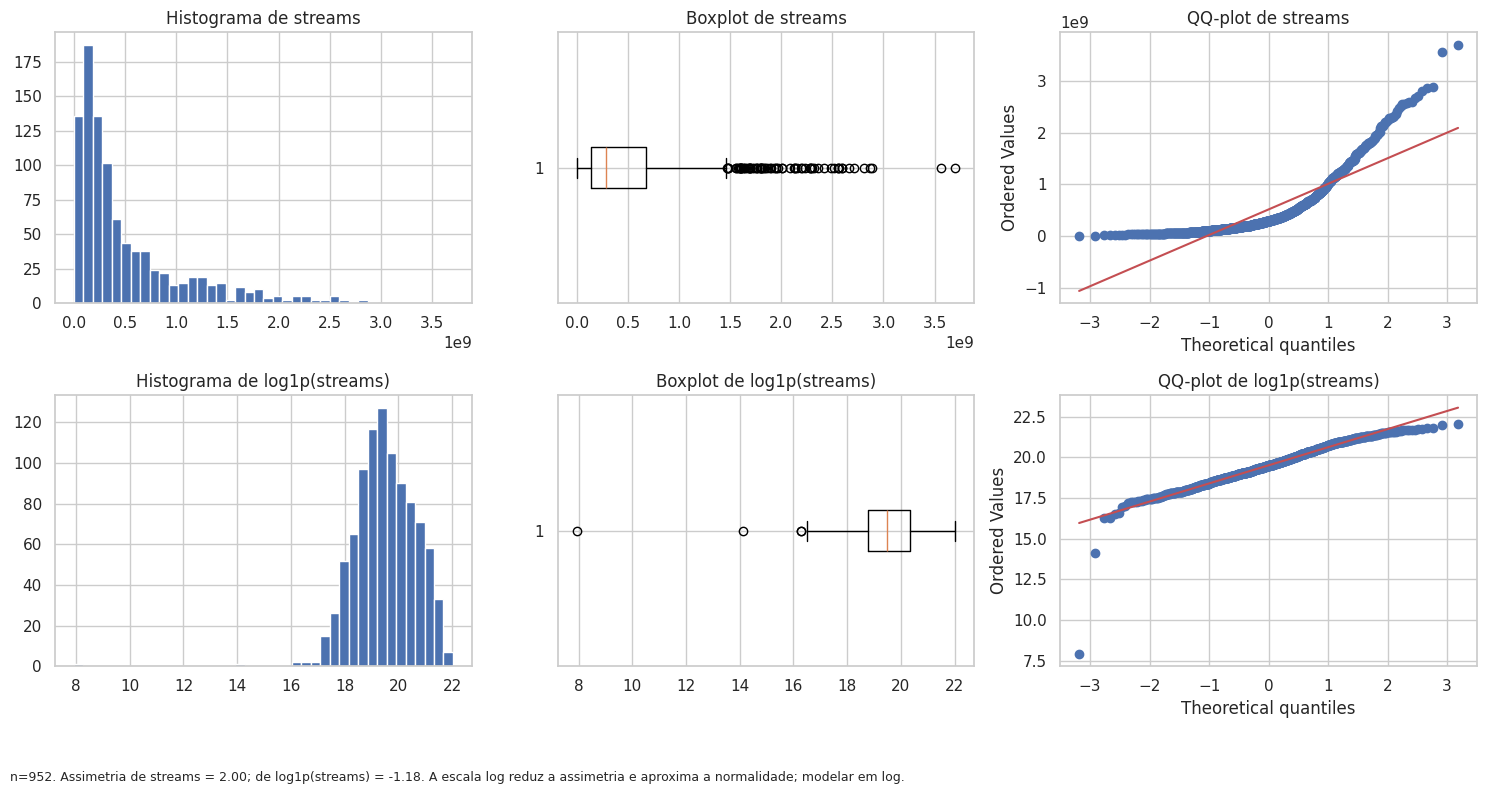

fig_target.png -> n=952. Assimetria de streams = 2.00; de log1p(streams) = -1.18. A escala log reduz a assimetria e aproxima a normalidade; modelar em log.


,count,mean,std,min,25%,50%,75%,max
streams,952.0,5.141374e+08,5.668569e+08,2762.0,141636175.0,290530915.0,673869022.0,3.703895e+09


In [2]:
s, ls = d["streams"], d["log_streams"]
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for r, (v, nome) in enumerate([(s, "streams"), (ls, "log1p(streams)")]):
    ax[r, 0].hist(v, bins=40, color="#4C72B0"); ax[r, 0].set_title(f"Histograma de {nome}")
    ax[r, 1].boxplot(v, vert=False); ax[r, 1].set_title(f"Boxplot de {nome}")
    stats.probplot(v, dist="norm", plot=ax[r, 2]); ax[r, 2].set_title(f"QQ-plot de {nome}")
sk, sk_log = stats.skew(s), stats.skew(ls)
save_fig(fig, "fig_target.png",
         f"n={len(s)}. Assimetria de streams = {sk:.2f}; de log1p(streams) = {sk_log:.2f}. "
         f"{'A escala log reduz a assimetria e aproxima a normalidade; modelar em log.' if abs(sk_log) < abs(sk) else 'A escala log não melhorou a assimetria; revisar.'}")
display(s.describe().to_frame("streams").T)

## 2. Distribuições dos atributos musicais e outliers (IQR)

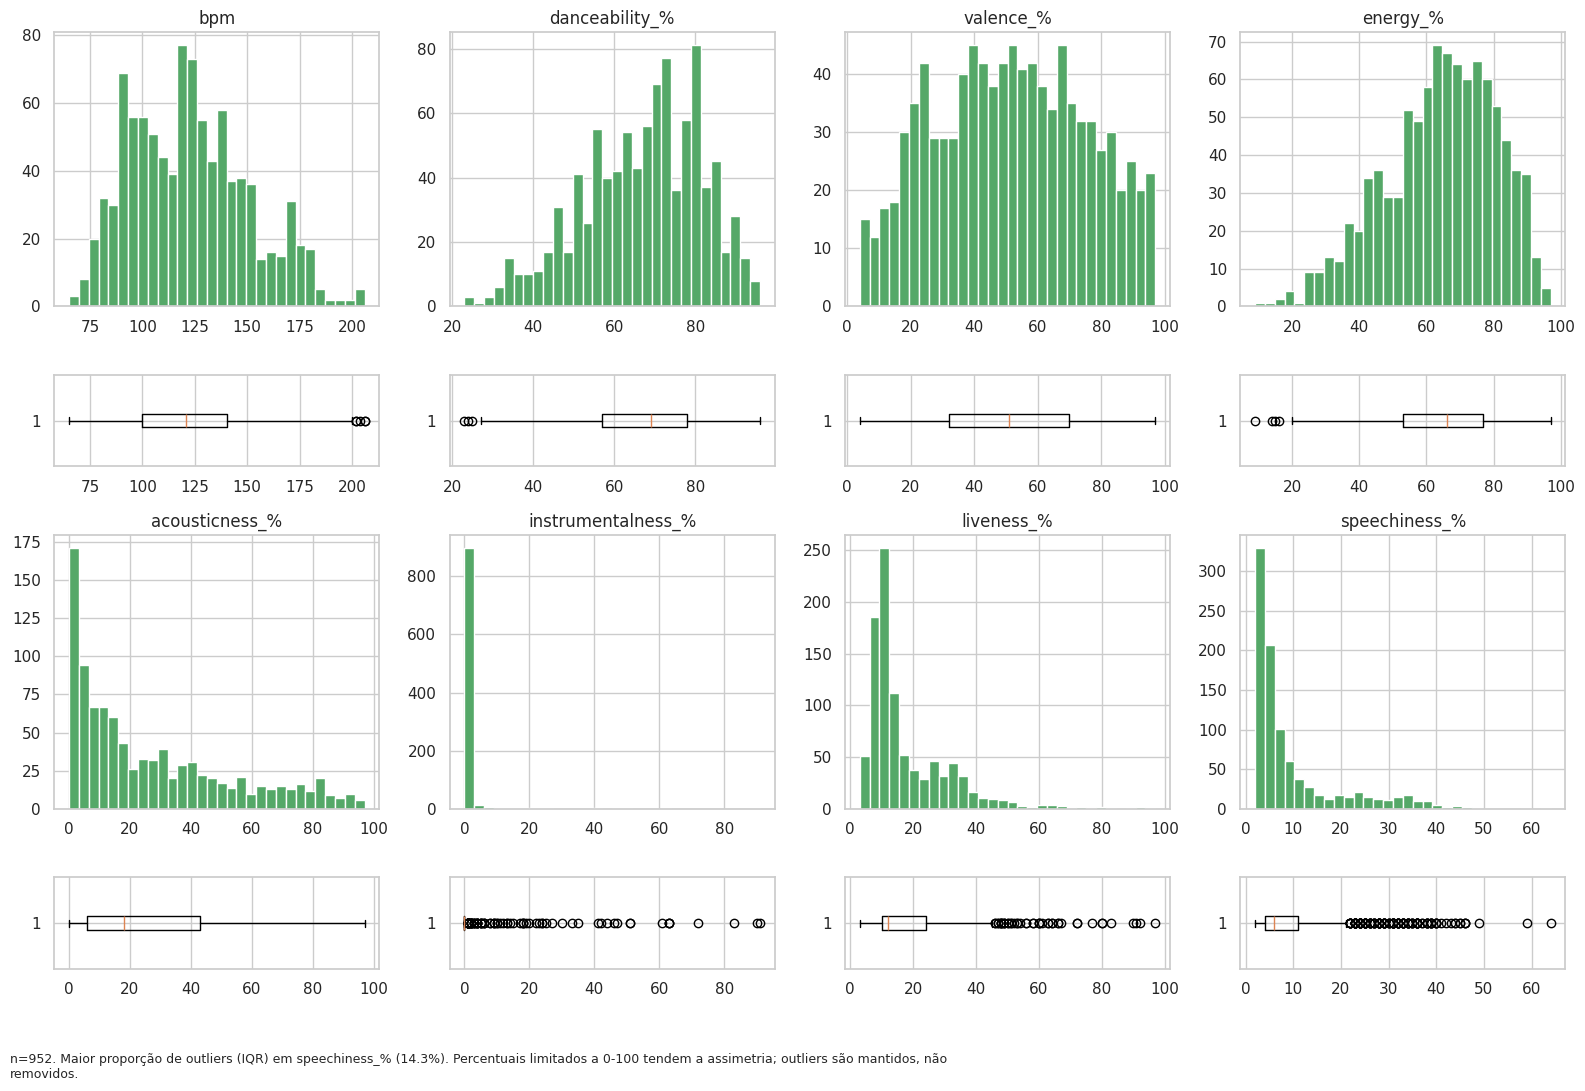

fig_features_dist.png -> n=952. Maior proporção de outliers (IQR) em speechiness_% (14.3%). Percentuais limitados a 0-100 tendem a assimetria; outliers são mantidos, não removidos.


,feature,n,q1,q3,fence_low,fence_high,n_outliers,pct_outliers
0,bpm,952,99.75,140.25,39.0,201.0,5,0.5
1,danceability_%,952,57.00,78.00,25.5,109.5,3,0.3
2,valence_%,952,32.00,70.00,-25.0,127.0,0,0.0
3,energy_%,952,53.00,77.00,17.0,113.0,4,0.4
4,acousticness_%,952,6.00,43.00,-49.5,98.5,0,0.0
5,instrumentalness_%,952,0.00,0.00,0.0,0.0,87,9.1
6,liveness_%,952,10.00,24.00,-11.0,45.0,44,4.6
7,speechiness_%,952,4.00,11.00,-6.5,21.5,136,14.3


In [3]:
fig, ax = plt.subplots(4, 4, figsize=(16, 11), gridspec_kw={"height_ratios": [3, 1, 3, 1]})
out_rows = []
for i, f in enumerate(NUM_FEATS):
    r, c = (i // 4) * 2, i % 4
    v = d[f].dropna()
    ax[r, c].hist(v, bins=30, color="#55A868"); ax[r, c].set_title(f)
    ax[r + 1, c].boxplot(v, vert=False)
    q1, q3 = v.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((v < lo) | (v > hi)).sum())
    out_rows.append(dict(feature=f, n=len(v), q1=q1, q3=q3, fence_low=lo, fence_high=hi,
                         n_outliers=n_out, pct_outliers=round(100 * n_out / len(v), 1)))
for j in range(len(NUM_FEATS), 8):
    ax[(j // 4) * 2, j % 4].axis("off"); ax[(j // 4) * 2 + 1, j % 4].axis("off")
out_tab = pd.DataFrame(out_rows)
out_tab.to_csv(TABLES_DIR / "tab_outliers_iqr.csv", index=False)
worst = out_tab.sort_values("pct_outliers", ascending=False).iloc[0]
save_fig(fig, "fig_features_dist.png",
         f"n={len(d)}. Maior proporção de outliers (IQR) em {worst['feature']} ({worst['pct_outliers']}%). "
         "Percentuais limitados a 0-100 tendem a assimetria; outliers são mantidos, não removidos.")
display(out_tab)

## 3. Correlação de Spearman com o alvo (IC por bootstrap de cluster + Holm)

,feature,n,rho,ci_low,ci_high,p_boot,nota,p_holm,ic_exclui_zero
0,bpm,952,0.0036,-0.0608,0.0715,0.940,,1.000,False
1,danceability_%,952,-0.0817,-0.1762,0.0008,0.052,,0.364,False
2,valence_%,952,-0.0378,-0.1068,0.0285,0.246,,0.984,False
3,energy_%,952,-0.0325,-0.0995,0.0323,0.306,,0.984,False
4,acousticness_%,952,-0.0604,-0.1476,0.0296,0.168,,0.840,False
5,instrumentalness_%,952,-0.0046,-0.0641,0.0557,0.884,,1.000,False
6,liveness_%,952,-0.0597,-0.1204,0.0006,0.054,,0.364,False
7,speechiness_%,952,-0.1078,-0.1929,-0.0297,0.012,,0.096,True
8,released_year,952,-0.6815,-0.7215,-0.6357,0.001,,0.010,True
9,artist_count,952,-0.1554,-0.2292,-0.0900,0.001,,0.010,True


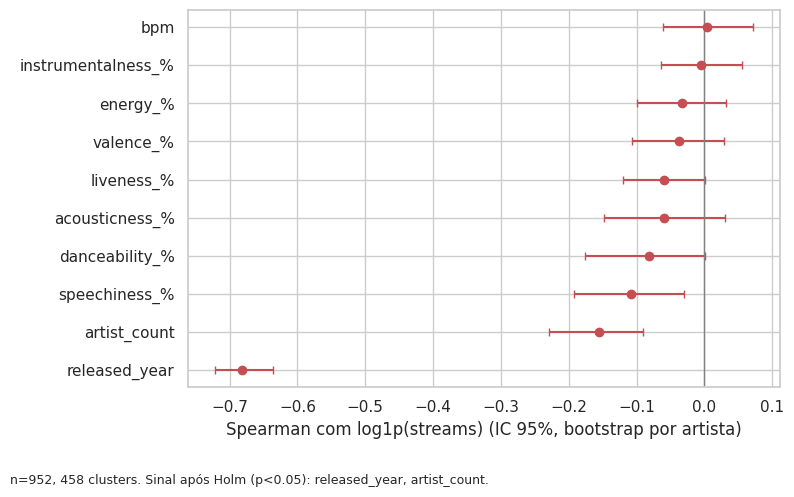

fig_spearman_target.png -> n=952, 458 clusters. Sinal após Holm (p<0.05): released_year, artist_count.


In [4]:
t_sp = spearman_table(d, ALL_NUM, N_BOOT, rng)
t_sp.to_csv(TABLES_DIR / "tab_spearman_target.csv", index=False)
display(t_sp.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
tt = t_sp.sort_values("rho")
ax.errorbar(tt["rho"], range(len(tt)), xerr=[tt["rho"] - tt["ci_low"], tt["ci_high"] - tt["rho"]],
            fmt="o", color="#C44E52", capsize=3)
ax.axvline(0, color="gray", lw=1); ax.set_yticks(range(len(tt))); ax.set_yticklabels(tt["feature"])
ax.set_xlabel("Spearman com log1p(streams) (IC 95%, bootstrap por artista)")
sig = t_sp[(t_sp["p_holm"] < 0.05) & t_sp["ic_exclui_zero"]]["feature"].tolist()
save_fig(fig, "fig_spearman_target.png",
         f"n={len(d)}, {d['main_artist'].nunique()} clusters. Sinal após Holm (p<0.05): "
         f"{', '.join(sig) if sig else 'nenhum atributo'}.")

## 4. Redundância entre atributos (matriz de Spearman e VIF)

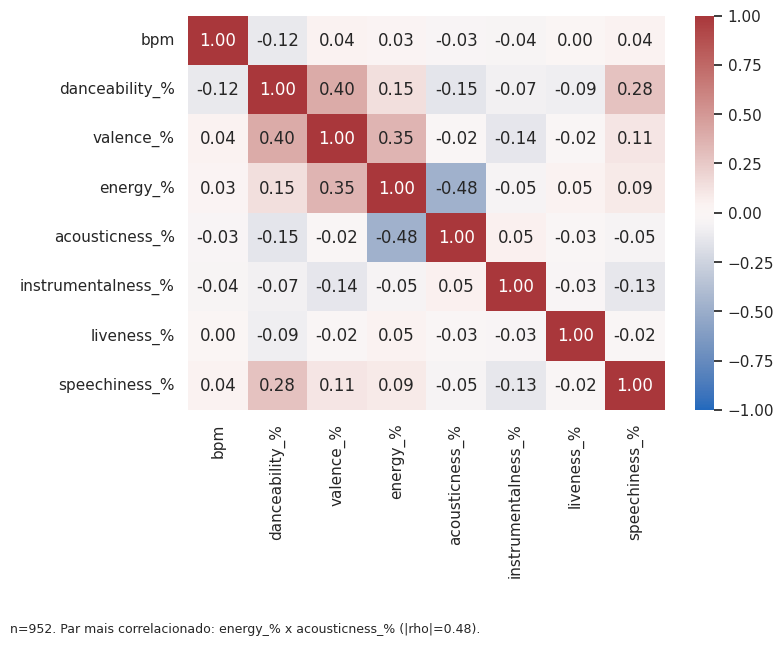

fig_corr_matrix.png -> n=952. Par mais correlacionado: energy_% x acousticness_% (|rho|=0.48).


,feature,vif
0,bpm,1.05
1,danceability_%,1.39
2,valence_%,1.45
3,energy_%,1.79
4,acousticness_%,1.64
5,instrumentalness_%,1.03
6,liveness_%,1.03
7,speechiness_%,1.05


In [5]:
corr = d[NUM_FEATS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
pairs = (corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().abs().sort_values(ascending=False))
top_pair = pairs.index[0]
save_fig(fig, "fig_corr_matrix.png",
         f"n={len(d)}. Par mais correlacionado: {top_pair[0]} x {top_pair[1]} (|rho|={pairs.iloc[0]:.2f}).")

def vif_table(X):
    Z = (X - X.mean()) / X.std(ddof=0)
    out = []
    for j, c in enumerate(Z.columns):
        y = Z[c].to_numpy(); A = np.column_stack([np.ones(len(Z)), Z.drop(columns=c).to_numpy()])
        beta, *_ = np.linalg.lstsq(A, y, rcond=None)
        r2 = 1 - ((y - A @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        out.append(dict(feature=c, vif=1 / (1 - r2)))
    return pd.DataFrame(out)

vif = vif_table(d[NUM_FEATS].dropna())
vif.to_csv(TABLES_DIR / "tab_vif.csv", index=False)
display(vif.round(2))

## 5. Relações não lineares (médias por faixa de quantil)

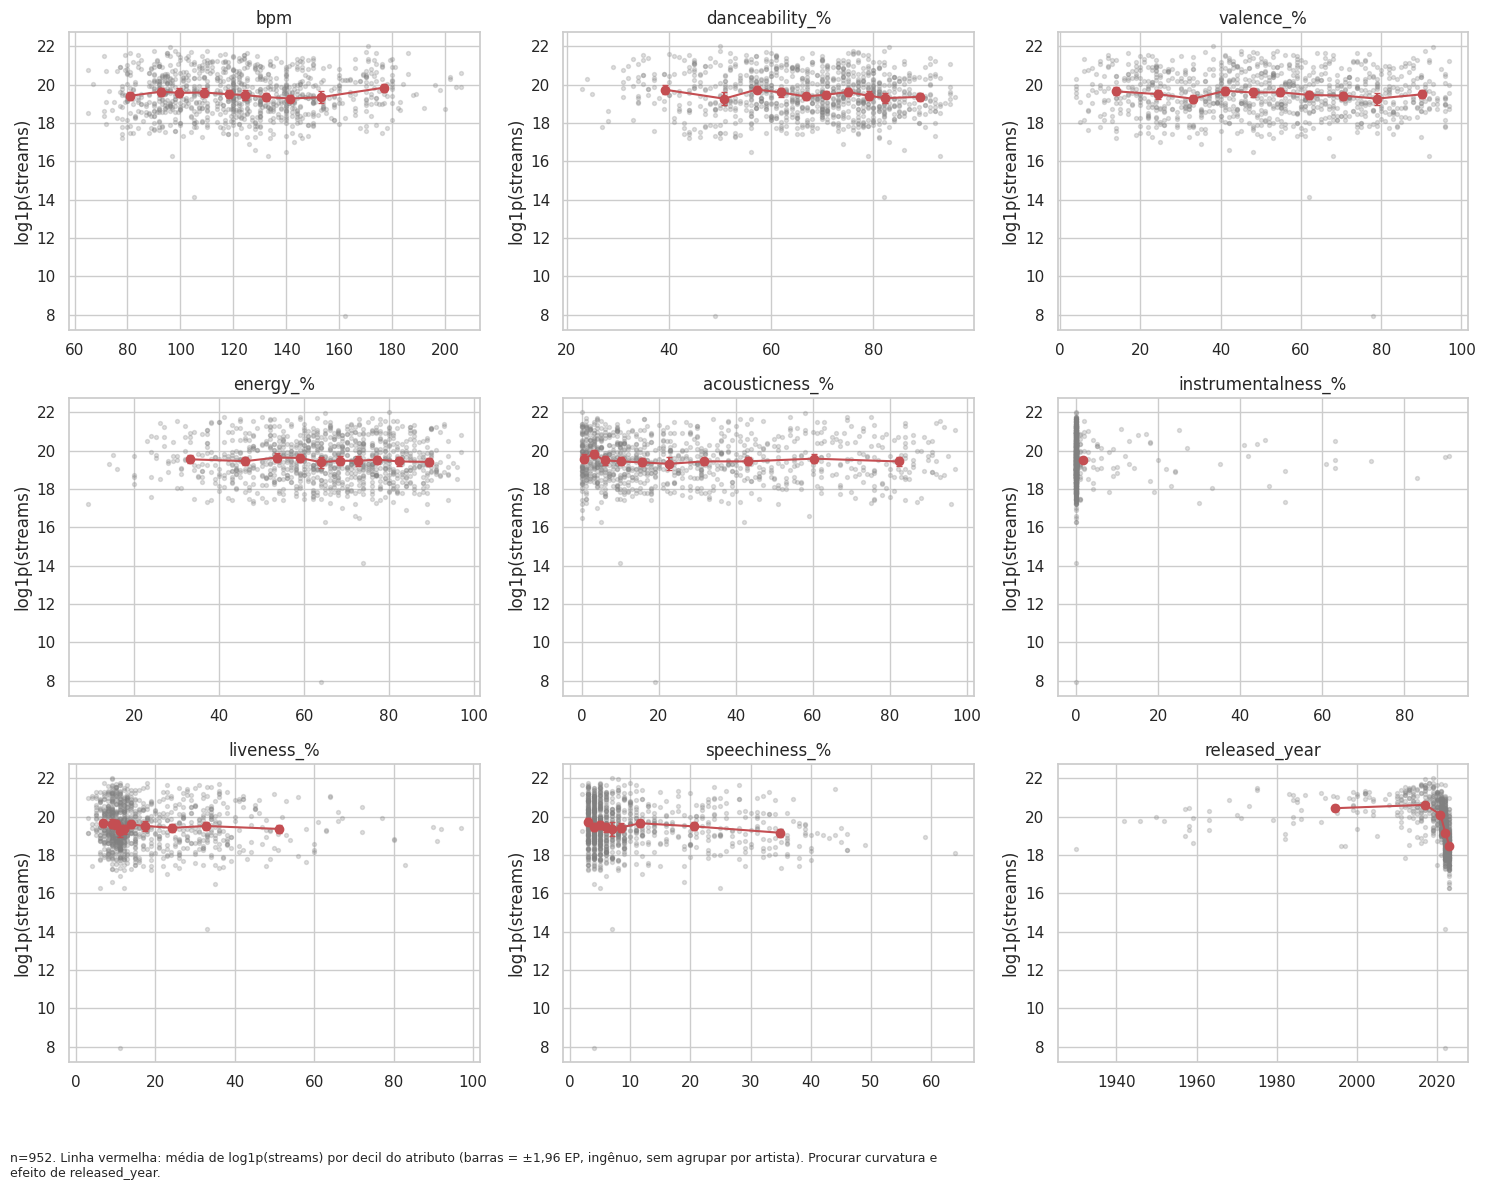

fig_scatter_grid.png -> n=952. Linha vermelha: média de log1p(streams) por decil do atributo (barras = ±1,96 EP, ingênuo, sem agrupar por artista). Procurar curvatura e efeito de released_year.


In [6]:
vars5 = NUM_FEATS + ["released_year"]
fig, ax = plt.subplots(3, 3, figsize=(15, 12))
for a, f in zip(ax.ravel(), vars5):
    sub = d[[f, "log_streams"]].dropna()
    a.scatter(sub[f], sub["log_streams"], s=8, alpha=.25, color="gray")
    bins = pd.qcut(sub[f], 10, duplicates="drop")
    g = sub.groupby(bins, observed=True).agg(x=(f, "mean"), y=("log_streams", "mean"),
                                              se=("log_streams", "sem"))
    a.errorbar(g["x"], g["y"], yerr=1.96 * g["se"], fmt="-o", color="#C44E52", capsize=2)
    a.set_title(f); a.set_ylabel("log1p(streams)")
save_fig(fig, "fig_scatter_grid.png",
         f"n={len(d)}. Linha vermelha: média de log1p(streams) por decil do atributo (barras = ±1,96 EP, "
         "ingênuo, sem agrupar por artista). Procurar curvatura e efeito de released_year.")

## 6. Categorias: `key`, `mode` e `release_period`

/tmp/ipykernel_56610/948238284.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  a.set_xticklabels([f"{o}\nn={counts.get(o, 0)}" for o in ordr], fontsize=8)


/tmp/ipykernel_56610/948238284.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  a.set_xticklabels([f"{o}\nn={counts.get(o, 0)}" for o in ordr], fontsize=8)


/tmp/ipykernel_56610/948238284.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  a.set_xticklabels([f"{o}\nn={counts.get(o, 0)}" for o in ordr], fontsize=8)


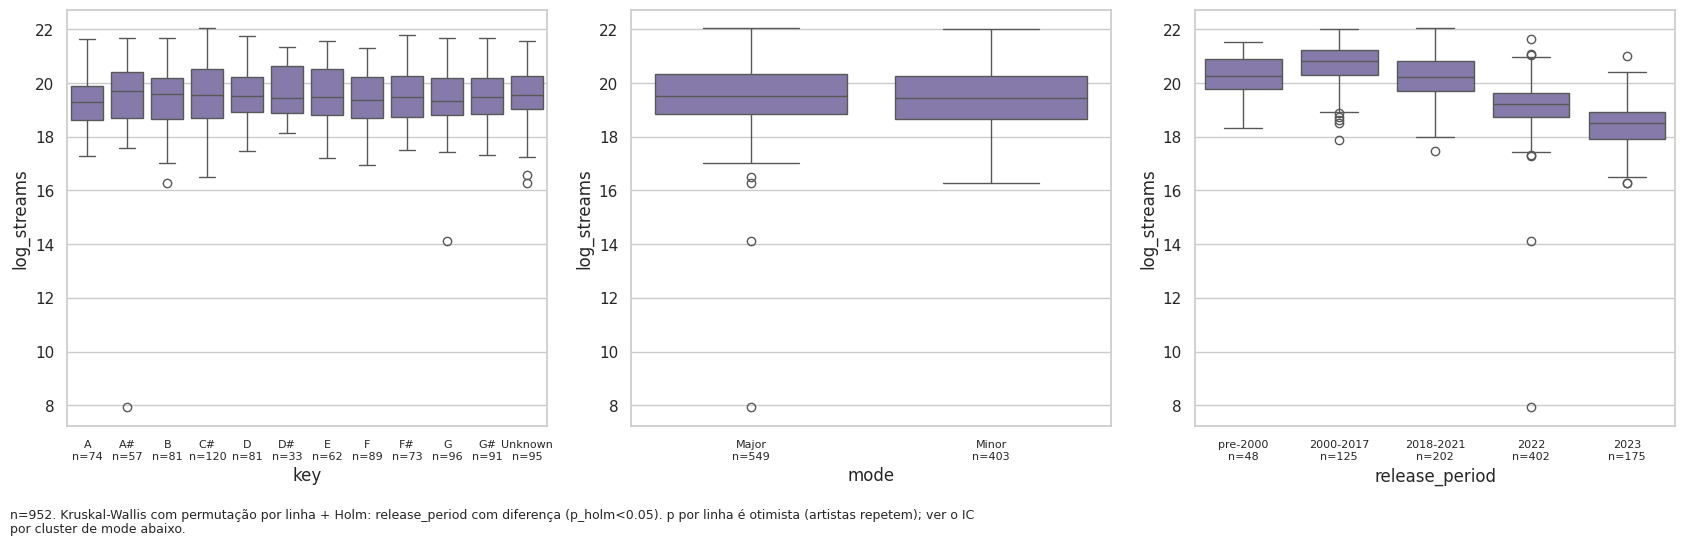

fig_categorical.png -> n=952. Kruskal-Wallis com permutação por linha + Holm: release_period com diferença (p_holm<0.05). p por linha é otimista (artistas repetem); ver o IC por cluster de mode abaixo.


,variavel,grupos,n,H_kruskal,epsilon2,p_perm,p_holm
0,key,12,952,5.3923,0.0000,0.9030,0.9030
1,mode,2,952,2.6573,0.0017,0.1029,0.2059
2,release_period,5,952,457.6426,0.4790,0.0005,0.0015


Diferença de medianas (mode), IC por cluster: {'dif_mediana': 0.10095712028934756, 'ci_low': -0.050774626670621534, 'ci_high': 0.2636164294001795, 'comparacao': 'Major - Minor'}


In [7]:
def kw_perm(sub, col, n_perm, rng):
    g = [v.to_numpy() for _, v in sub.groupby(col, observed=True)["log_streams"] if len(v) >= 2]
    H = stats.kruskal(*g)[0]; k = len(g); n = sum(len(x) for x in g)
    eps2 = max(0.0, (H - k + 1) / (n - k))
    y = sub["log_streams"].to_numpy(); lab = sub[col].to_numpy(); cnt = 0
    keep = sub.groupby(col)["log_streams"].transform("size") >= 2
    y, lab = y[keep.to_numpy()], lab[keep.to_numpy()]
    for _ in range(n_perm):
        p = rng.permutation(lab)
        Hp = stats.kruskal(*[y[p == l] for l in np.unique(p)])[0]
        cnt += Hp >= H
    return H, eps2, (cnt + 1) / (n_perm + 1), k, n

cat = d.copy()
key_order = sorted([k for k in cat["key"].unique() if k != "Unknown"]) + (["Unknown"] if "Unknown" in set(cat["key"]) else [])
orders = {"key": key_order, "mode": sorted(cat["mode"].dropna().unique()),
          "release_period": [p for p in PERIODS if p in set(cat["release_period"].dropna())]}
fig, ax = plt.subplots(1, 3, figsize=(17, 5.5))
rows = []
for a, col in zip(ax, ["key", "mode", "release_period"]):
    sub = cat.dropna(subset=[col])
    ordr = orders[col]
    sns.boxplot(data=sub, x=col, y="log_streams", order=ordr, ax=a, color="#8172B2")
    counts = sub[col].value_counts()
    a.set_xticklabels([f"{o}\nn={counts.get(o, 0)}" for o in ordr], fontsize=8)
    H, eps2, p, k, n = kw_perm(sub, col, N_PERM, rng)
    rows.append(dict(variavel=col, grupos=k, n=n, H_kruskal=H, epsilon2=eps2, p_perm=p))
t_cat = pd.DataFrame(rows)
t_cat["p_holm"] = holm(t_cat["p_perm"])

# mode: diferença de medianas com IC por bootstrap de cluster
sub = cat.dropna(subset=["mode"]).reset_index(drop=True)
lv = orders["mode"]
if len(lv) == 2:
    idxs = boot_indices(clusters(sub), N_BOOT, rng); yy = sub["log_streams"].to_numpy(); mm = sub["mode"].to_numpy()
    def dmed(i):
        a_, b_ = yy[i][mm[i] == lv[0]], yy[i][mm[i] == lv[1]]
        return np.median(a_) - np.median(b_) if len(a_) and len(b_) else np.nan
    bs = np.array([dmed(i) for i in idxs])
    mode_diff = dict(dif_mediana=dmed(np.arange(len(sub))), ci_low=np.nanpercentile(bs, 2.5), ci_high=np.nanpercentile(bs, 97.5),
                     comparacao=f"{lv[0]} - {lv[1]}")
else:
    mode_diff = None
t_cat.to_csv(TABLES_DIR / "tab_categorical.csv", index=False)
sigc = t_cat[t_cat["p_holm"] < 0.05]["variavel"].tolist()
save_fig(fig, "fig_categorical.png",
         f"n={len(cat)}. Kruskal-Wallis com permutação por linha + Holm: "
         f"{', '.join(sigc) if sigc else 'nenhuma variável categórica'} com diferença (p_holm<0.05). "
         "p por linha é otimista (artistas repetem); ver o IC por cluster de mode abaixo.")
display(t_cat.round(4))
print("Diferença de medianas (mode), IC por cluster:", mode_diff)

## 7. Concentração por artista

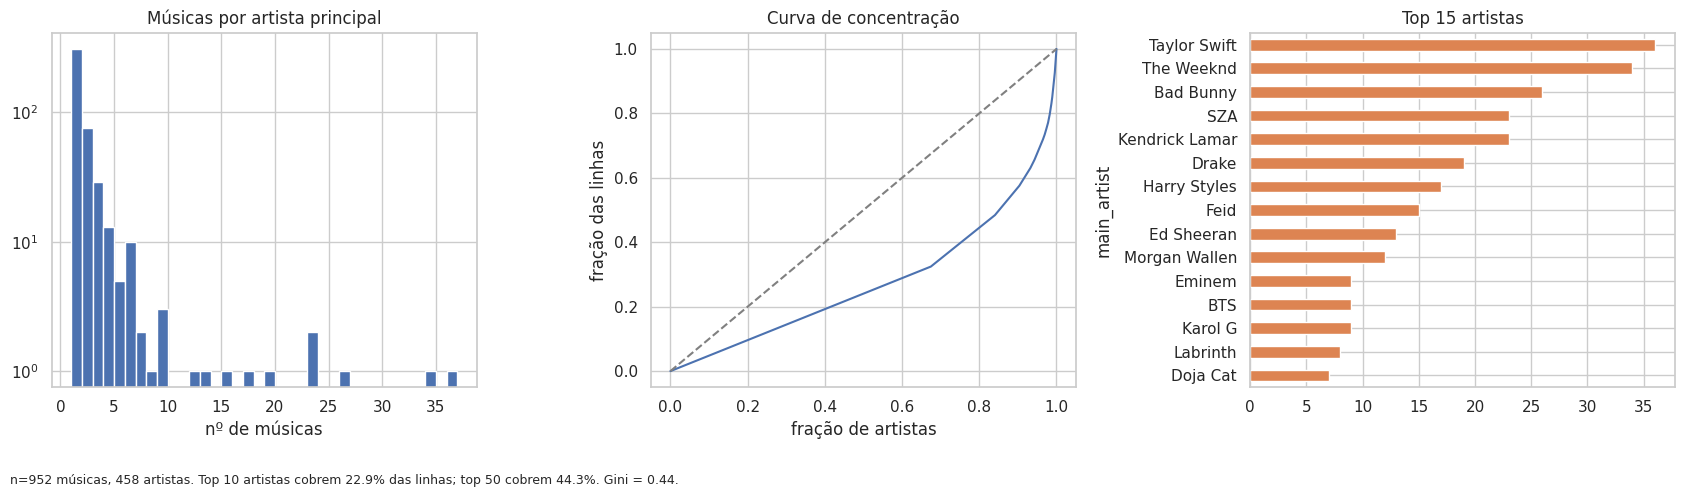

fig_artist_conc.png -> n=952 músicas, 458 artistas. Top 10 artistas cobrem 22.9% das linhas; top 50 cobrem 44.3%. Gini = 0.44.


,top_n,pct_linhas
0,1,3.8
1,5,14.9
2,10,22.9
3,20,30.6
4,50,44.3
5,100,57.2


In [8]:
cnt = d["main_artist"].value_counts()
share = cnt.cumsum() / cnt.sum()
topn = [1, 5, 10, 20, 50, 100]
conc = pd.DataFrame(dict(top_n=topn, pct_linhas=[round(100 * share.iloc[min(n, len(share)) - 1], 1) for n in topn]))
conc.to_csv(TABLES_DIR / "tab_artist_conc.csv", index=False)
x = np.sort(cnt.to_numpy()); lorenz = np.concatenate([[0], np.cumsum(x) / x.sum()])
trap = getattr(np, "trapezoid", None) or np.trapz
gini = 1 - 2 * trap(lorenz, dx=1 / len(x))

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
ax[0].hist(cnt, bins=range(1, cnt.max() + 2), color="#4C72B0"); ax[0].set_yscale("log")
ax[0].set_title("Músicas por artista principal"); ax[0].set_xlabel("nº de músicas")
ax[1].plot(np.linspace(0, 1, len(lorenz)), lorenz, label="Lorenz"); ax[1].plot([0, 1], [0, 1], "--", color="gray")
ax[1].set_title("Curva de concentração"); ax[1].set_xlabel("fração de artistas"); ax[1].set_ylabel("fração das linhas")
cnt.head(15)[::-1].plot.barh(ax=ax[2], color="#DD8452"); ax[2].set_title("Top 15 artistas")
save_fig(fig, "fig_artist_conc.png",
         f"n={len(d)} músicas, {len(cnt)} artistas. Top 10 artistas cobrem {conc.loc[conc.top_n == 10, 'pct_linhas'].iloc[0]}% das linhas; "
         f"top 50 cobrem {conc.loc[conc.top_n == 50, 'pct_linhas'].iloc[0]}%. Gini = {gini:.2f}.")
display(conc)

## 8. Robustez: por período e sem os maiores artistas

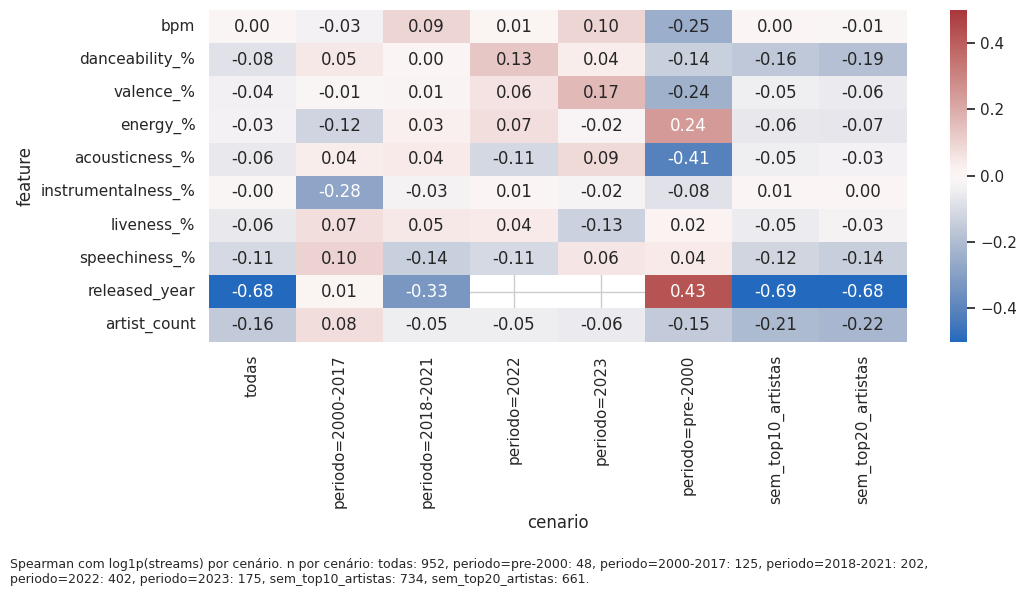

fig_robustness.png -> Spearman com log1p(streams) por cenário. n por cenário: todas: 952, periodo=pre-2000: 48, periodo=2000-2017: 125, periodo=2018-2021: 202, periodo=2022: 402, periodo=2023: 175, sem_top10_artistas: 734, sem_top20_artistas: 661.


,cenario,feature,n,rho,ci_low,ci_high,p_boot,nota,p_holm,ic_exclui_zero
0,todas,bpm,952,0.004,-0.062,0.072,0.956,,1.000,False
1,todas,danceability_%,952,-0.082,-0.169,0.001,0.056,,0.392,False
2,todas,valence_%,952,-0.038,-0.107,0.027,0.232,,1.000,False
3,todas,energy_%,952,-0.032,-0.105,0.037,0.352,,1.000,False
4,todas,acousticness_%,952,-0.060,-0.141,0.023,0.208,,1.000,False
5,todas,instrumentalness_%,952,-0.005,-0.065,0.064,0.868,,1.000,False
6,todas,liveness_%,952,-0.060,-0.115,0.010,0.076,,0.456,False
7,todas,speechiness_%,952,-0.108,-0.186,-0.034,0.002,,0.020,True
8,todas,released_year,952,-0.682,-0.717,-0.636,0.002,,0.020,True
9,todas,artist_count,952,-0.155,-0.240,-0.092,0.002,,0.020,True


In [9]:
cnt_all = d["main_artist"].value_counts()
scen = {"todas": d}
for p in PERIODS:
    sub = d[d["release_period"] == p]
    if len(sub) >= 40 and sub["main_artist"].nunique() >= 10:
        scen[f"periodo={p}"] = sub
for k in (10, 20):
    scen[f"sem_top{k}_artistas"] = d[~d["main_artist"].isin(cnt_all.head(k).index)]

rob = []
for name, sub in scen.items():
    t = spearman_table(sub, ALL_NUM, N_BOOT_ROBUST, rng); t.insert(0, "cenario", name)
    rob.append(t)
rob = pd.concat(rob, ignore_index=True)
rob.to_csv(TABLES_DIR / "tab_robustness.csv", index=False)

piv = rob.pivot(index="feature", columns="cenario", values="rho").reindex(ALL_NUM)
piv = piv[["todas"] + [c for c in piv.columns if c != "todas"]]
fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(piv, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-.5, vmax=.5, ax=ax)
ns = ", ".join(f"{k}: {len(v)}" for k, v in scen.items())
save_fig(fig, "fig_robustness.png", f"Spearman com log1p(streams) por cenário. n por cenário: {ns}.")
display(rob.round(3).head(len(ALL_NUM)))

## 9. Viés do `streams` acumulado: o ano de lançamento domina?
`streams` é acumulado, então músicas antigas tiveram mais tempo para acumular. Abaixo, o Spearman de cada atributo antes e depois de remover o efeito de `released_year` (correlação parcial por postos).

In [10]:
def partial_spearman(x, y, z):
    rx, ry, rz = (stats.rankdata(v) for v in (x, y, z))
    A = np.column_stack([np.ones(len(rz)), rz])
    res = lambda v: v - A @ np.linalg.lstsq(A, v, rcond=None)[0]
    return np.corrcoef(res(rx), res(ry))[0, 1]

sub = d.dropna(subset=["released_year"]).reset_index(drop=True)
idxs = boot_indices(clusters(sub), N_BOOT_ROBUST, rng)
y, z = sub["log_streams"].to_numpy(), sub["released_year"].to_numpy(float)
rows = []
for f in [c for c in ALL_NUM if c != "released_year"]:
    x = sub[f].to_numpy(float)
    bs = np.array([partial_spearman(x[i], y[i], z[i]) for i in idxs])
    rows.append(dict(feature=f, rho_bruto=spearman(x, y), rho_parcial_ano=partial_spearman(x, y, z),
                     ci_low=np.percentile(bs, 2.5), ci_high=np.percentile(bs, 97.5)))
t_part = pd.DataFrame(rows)
t_part["ic_exclui_zero"] = (t_part["ci_low"] > 0) | (t_part["ci_high"] < 0)
t_part.to_csv(TABLES_DIR / "tab_partial_year.csv", index=False)
rho_year = t_sp.loc[t_sp.feature == "released_year", "rho"].iloc[0]
display(t_part.round(3))
print(f"Spearman(released_year, log_streams) = {rho_year:.3f}")

,feature,rho_bruto,rho_parcial_ano,ci_low,ci_high,ic_exclui_zero
0,bpm,0.004,0.035,-0.030,0.099,False
1,danceability_%,-0.082,0.071,-0.013,0.139,False
2,valence_%,-0.038,0.017,-0.055,0.088,False
3,energy_%,-0.032,0.032,-0.041,0.095,False
4,acousticness_%,-0.060,-0.070,-0.153,0.023,False
5,instrumentalness_%,-0.005,-0.054,-0.114,0.001,False
6,liveness_%,-0.060,-0.003,-0.065,0.063,False
7,speechiness_%,-0.108,-0.036,-0.126,0.028,False
8,artist_count,-0.155,-0.032,-0.109,0.032,False


Spearman(released_year, log_streams) = -0.682


## 10. Síntese automática (`reports/eda_summary.md`) e legendas

In [11]:
base = t_sp.set_index("feature")
sig = base[(base["p_holm"] < 0.05) & base["ic_exclui_zero"]]
sig_music = [f for f in sig.index if f in NUM_FEATS]
per_cols = [c for c in piv.columns if c.startswith("periodo=")]

lines = ["# Síntese da análise exploratória", "",
         f"Base: {len(d)} músicas com `streams` válido, {d['main_artist'].nunique()} artistas principais. "
         "Incerteza por bootstrap de cluster (artista principal); p ajustados por Holm.", "",
         "## Quais atributos mostram sinal"]
if sig_music:
    lines += [f"- `{f}`: rho = {sig.loc[f,'rho']:.2f} (IC {sig.loc[f,'ci_low']:.2f} a {sig.loc[f,'ci_high']:.2f}), p_holm = {sig.loc[f,'p_holm']:.3g}" for f in sig_music]
else:
    lines += ["- Nenhum atributo musical tem Spearman com IC excluindo zero após Holm. Sinal preditivo fraco é um resultado válido."]
ctx = [f for f in sig.index if f in CONTEXT]
if ctx:
    lines += ["", "Contexto com sinal: " + ", ".join(f"`{f}` (rho = {sig.loc[f,'rho']:.2f})" for f in ctx)]

lines += ["", "## O que muda ao isolar período ou retirar grandes artistas"]
for f in NUM_FEATS:
    r_all = piv.loc[f, "todas"]
    cols = {c: piv.loc[f, c] for c in per_cols + [c for c in piv.columns if c.startswith("sem_top")] if not np.isnan(piv.loc[f, c])}
    flips = [c for c, v in cols.items() if abs(r_all) > 0.05 and np.sign(v) != np.sign(r_all) and abs(v) > 0.05]
    weak = [c for c, v in cols.items() if abs(r_all) > 0.05 and abs(v) < abs(r_all) / 2]
    if f in sig_music or flips or weak:
        lines.append(f"- `{f}` (todas: {r_all:.2f}): " +
                     (f"troca de sinal em {', '.join(flips)}. " if flips else "") +
                     (f"cai a menos da metade em {', '.join(weak)}." if weak else ("" if flips else "estável nos cenários testados.")))
if len(lines) and lines[-1].startswith("## "):
    lines.append("- Nenhum atributo se destaca; ver `tab_robustness.csv`.")

lines += ["", "## Viés de `streams` acumulado",
          f"- Spearman(`released_year`, log_streams) = {rho_year:.2f}.",
          "- Atributos cujo IC ainda exclui zero depois de controlar o ano: " +
          (", ".join(f"`{f}`" for f in t_part[t_part.ic_exclui_zero].feature) or "nenhum") + ".",
          "", "## Categorias",
          *[f"- `{r.variavel}`: epsilon² = {r.epsilon2:.3f}, p_holm = {r.p_holm:.3g}" for r in t_cat.itertuples()],
          "", "## Concentração por artista",
          f"- Top 10 artistas = {conc.loc[conc.top_n==10,'pct_linhas'].iloc[0]}% das linhas; top 50 = {conc.loc[conc.top_n==50,'pct_linhas'].iloc[0]}%.",
          "", "## Hipóteses do roadmap",
          "- Mapear aqui as hipóteses 1 a 4 do `roadmap.md` contra as evidências acima (o notebook não lê o roadmap).",
          "", "## Limitações",
          "- A amostra são músicas já populares (seleção pelo alvo), então correlações tendem a ser atenuadas.",
          "- `streams` é acumulado e depende da idade da música.",
          "- p de testes por grupo (seção 6) permutam linhas e são otimistas; os ICs por cluster são a referência.",
          "- Correlação não é causa."]
(REPORTS_DIR / "eda_summary.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
pd.DataFrame(CAPTIONS).to_csv(TABLES_DIR / "figure_captions.csv", index=False)
print("\n".join(lines))

# Síntese da análise exploratória

Base: 952 músicas com `streams` válido, 458 artistas principais. Incerteza por bootstrap de cluster (artista principal); p ajustados por Holm.

## Quais atributos mostram sinal
- Nenhum atributo musical tem Spearman com IC excluindo zero após Holm. Sinal preditivo fraco é um resultado válido.

Contexto com sinal: `released_year` (rho = -0.68), `artist_count` (rho = -0.16)

## O que muda ao isolar período ou retirar grandes artistas
- `danceability_%` (todas: -0.08): troca de sinal em periodo=2000-2017, periodo=2022. cai a menos da metade em periodo=2018-2021, periodo=2023.
- `acousticness_%` (todas: -0.06): troca de sinal em periodo=2023. 
- `liveness_%` (todas: -0.06): troca de sinal em periodo=2000-2017. cai a menos da metade em periodo=pre-2000, sem_top20_artistas.
- `speechiness_%` (todas: -0.11): troca de sinal em periodo=2000-2017, periodo=2023. cai a menos da metade em periodo=pre-2000.

## Viés de `streams` acumulado
- Spearman(`released_year`

## Pendências
- Mapear as hipóteses 1 a 4 do roadmap na síntese.
- Decidir a forma do período de lançamento no modelo (`released_year`, `release_period` ou `age_years`).